# Pokémon Battles Prediction 2026

Class: Foundamentals Of Data Science \
Subject: Team Challenge  \
Prof: Indro Spinelli  \
By: Diana Sarsembayeva \
website: https://www.kaggle.com/competitions/fds-pokemon-battles-prediction-2026

### The Challenge 
The goal is to build a classification model that predicts the winner of a Pokémon battle from the perspective of "Player 1." 

### The Data 
Dataset Files: \
train.jsonl — training data \(10 000 battles\) \
test.jsonl — test data \( 5,000 battles \) \
sample_submission.csv — submission template \
type_chart_gen2.csv — Pokémon type matchups

type_chart : Contains attacking_type, defending_type, and multiplier. It covers 17 types and provides a way to calculate type advantages and disadvantages.

Field: \
battle_id - Unique battle identifier \
player_won - Whether the player won	\
p1_team_details - Six Pokémon on the player's team \(Team strength, types, items, lead\) \
p2_lead_details - Opponent's lead Pokémon \
battle_timeline - Turn-by-turn battle information \(Battle progress, damage-related clues, status and move patterns \)


**the team information describes the initial conditions, while the timeline describes what happened during the battle**

What is inside the timeline? \
Each turn can contain:
- p1_pokemon_state and p2_pokemon_state: active Pokémon, remaining HP, status conditions, effects and stat boosts. 
- p1_move_details and p2_move_details: move type, category, power, accuracy and priority.
- turn: the turn number.

note: These fields can provide valuable information, but be careful: a battle's timeline may reflect events that occur after the fight begins. When using timeline features, check that you only use information available in both training and test records and that the competition's prediction setup permits it.

For instance, the player's HP at the beginning of a battle is different from the player's HP after several turns. The latter may tell you much more about how the battle is going.

--------

### Phase 1 - Understand the problem

Problem type: supervised learning.

ML task: binary classification.

Target: `player_won`.

Positive class: `1` — Player 1 won.

Negative class: `0` — Player 1 lost.

Training data: 10,000 battles with labels.

Test data: 5,000 battles without labels.

Goal: predict `player_won` for the test battles.

------

### Phase 2 - Loading and Understanding the Data

The goal is to understand what you loaded before deciding how to turn it into features.

In [1]:
# import the libraries 
import json
import pandas as pd
import numpy as np 
from pathlib import Path

In [2]:
train_file_path = Path("train.jsonl")
test_file_path = Path("test.jsonl")

def load_json(path): 
    with open(path, "r", encoding="utf-8") as file: 
        return [json.loads(line) for line in file if line.strip()]
    
train_data = load_json(train_file_path)
test_data = load_json(test_file_path)

print("Training battles:", len(train_data))
print("Test battles:", len(test_data))

Training battles: 10000
Test battles: 5000


In [3]:
# exploring the first battle
battle = train_data[0]

In [4]:
# battle in a readable format
print("--- First train battle ---")
print(json.dumps(battle, indent=4))

--- First train battle ---
{
    "battle_id": 0,
    "p1_team_details": [
        {
            "name": "tyranitar",
            "level": 100,
            "types": [
                "dark",
                "rock"
            ],
            "base_hp": 100,
            "base_atk": 134,
            "base_def": 110,
            "base_spa": 95,
            "base_spd": 100,
            "base_spe": 61,
            "item": "leftovers"
        },
        {
            "name": "typhlosion",
            "level": 100,
            "types": [
                "fire",
                "notype"
            ],
            "base_hp": 78,
            "base_atk": 84,
            "base_def": 78,
            "base_spa": 109,
            "base_spd": 85,
            "base_spe": 100,
            "item": "mintberry"
        },
        {
            "name": "golem",
            "level": 100,
            "types": [
                "ground",
                "rock"
            ],
            "base_hp": 80,
          

Understanding the nested structure (before deciding how to transform it)

In [5]:
# Look at the fields in the first training battle
print("Top-level keys:")
print(battle.keys())


Top-level keys:
dict_keys(['battle_id', 'p1_team_details', 'p2_lead_details', 'battle_timeline', 'player_won'])


In [6]:
# Look at the type and a short example of each field
for field, value in battle.items():
    print(field, type(value))

print()
print("Team size:", len(battle["p1_team_details"]))
print("Player lead:", battle["p1_team_details"][0])
print("Opponent lead:", battle["p2_lead_details"])
print("Number of turns:", len(battle["battle_timeline"]))

battle_id <class 'int'>
p1_team_details <class 'list'>
p2_lead_details <class 'dict'>
battle_timeline <class 'list'>
player_won <class 'int'>

Team size: 6
Player lead: {'name': 'tyranitar', 'level': 100, 'types': ['dark', 'rock'], 'base_hp': 100, 'base_atk': 134, 'base_def': 110, 'base_spa': 95, 'base_spd': 100, 'base_spe': 61, 'item': 'leftovers'}
Opponent lead: {'name': 'forretress', 'level': 100, 'types': ['bug', 'steel'], 'base_hp': 75, 'base_atk': 90, 'base_def': 140, 'base_spa': 60, 'base_spd': 60, 'base_spe': 40}
Number of turns: 30


In [7]:
sample_submission = 'sample_submission.csv'

In [8]:
type_chart =  pd.read_csv("type_chart_gen2.csv")

In [9]:
print( type_chart.shape)

(110, 3)


In [10]:
type_chart.head()

,attacking_type,defending_type,multiplier
0,normal,rock,0.5
1,normal,ghost,0.0
2,normal,steel,0.5
3,fire,fire,0.5
4,fire,water,0.5


In [11]:
type_chart.columns

Index(['attacking_type', 'defending_type', 'multiplier'], dtype='str')

----

### Phase 3 — Exploratory Data Analysis \(EDA\)

#### 3.1. Checking the training labels (target variable)

Check how many battles Player 1 won and lost

In [12]:
from collections import Counter

Note: The Counter class automatically counts the frequency of hashable items in an iterable (like a list, string, or tuple) and stores them as key-value pairs in a dictionary subclass. 

In [13]:
target_counts = Counter(
    battle["player_won"] for battle in train_data
)
# battle["player_won"] extracts the target value from each battle.
print(target_counts)

Counter({0: 5000, 1: 5000})



- True: the player won 5,000 battles.
- False: the player lost 5,000 battles.

The training dataset is perfectly balanced: 5,000 battles belong to class 0 and 5,000 to class 1, each representing 50% of the data. Therefore, always predicting the majority class gives a baseline accuracy of 50%.

#### 3.2. Check record consistency


In [14]:
# Check missing values
def check_missing_values(records):
    missing = Counter()

    for battle in records:
        for key, value in battle.items():
            if value is None:
                missing[key] += 1

    return missing

print("Train:", check_missing_values(train_data))
print("Test:", check_missing_values(test_data))

Train: Counter()
Test: Counter()


In [15]:
# Check duplicate records
def count_duplicate_records(records):
    record_counts = Counter(
        json.dumps(battle, sort_keys=True)
        for battle in records
    )

    return sum(count - 1 for count in record_counts.values())

print("Duplicate train records:", count_duplicate_records(train_data))
print("Duplicate test records:", count_duplicate_records(test_data))

Duplicate train records: 0
Duplicate test records: 0


In [16]:
# Check whether battles have the same fields
print(train_data[0].keys())
print(test_data[0].keys())

dict_keys(['battle_id', 'p1_team_details', 'p2_lead_details', 'battle_timeline', 'player_won'])
dict_keys(['battle_id', 'p1_team_details', 'p2_lead_details', 'battle_timeline'])


In [17]:
train_keys = set(train_data[0].keys())
test_keys = set(test_data[0].keys())

print("Fields only in train:", train_keys - test_keys)
print("Fields only in test:", test_keys - train_keys)

# checking wheather the training and test records have the same top-level structure
# > This matters because the model needs compatible input features in both datasets.

Fields only in train: {'player_won'}
Fields only in test: set()


In [18]:
# Check Player 1's team size in both datasets
train_team_sizes = Counter(
    len(battle["p1_team_details"])
    for battle in train_data
)

test_team_sizes = Counter(
    len(battle["p1_team_details"])
    for battle in test_data
)

print("Train team sizes:", train_team_sizes)
print("Test team sizes:", test_team_sizes)

Train team sizes: Counter({6: 10000})
Test team sizes: Counter({6: 5000})


In [19]:
# check the number of timline events in both datasets
train_timeline_lengths = Counter(
    len(battle["battle_timeline"])
    for battle in train_data
)

test_timeline_lengths = Counter(
    len(battle["battle_timeline"])
    for battle in test_data
)

print("Train timeline lengths:", train_timeline_lengths)
print("Test timeline lengths:", test_timeline_lengths)

Train timeline lengths: Counter({30: 10000})
Test timeline lengths: Counter({30: 5000})


In [20]:
# Check that timeline events have the expected fields
print(train_data[0]["battle_timeline"][0].keys())

dict_keys(['turn', 'p1_pokemon_state', 'p1_move_details', 'p2_pokemon_state', 'p2_move_details'])


In [21]:
print(test_data[0]["battle_timeline"][0].keys())

dict_keys(['turn', 'p1_pokemon_state', 'p1_move_details', 'p2_pokemon_state', 'p2_move_details'])


#### 3.3 Explore Player 1's initial team
Question: What characteristics do Player 1's Pokémon have?

In [22]:
# We need to know how the data is stored before deciding how to count or summarize it.

# Select the first battle
battle = train_data[0]

# Select the first Pokémon in Player 1's team
pokemon = battle["p1_team_details"][0]

print(pokemon)
print("\n ---- the keys: ----")
print(pokemon.keys())
print("\n types of the pokemon:", pokemon["types"])

{'name': 'tyranitar', 'level': 100, 'types': ['dark', 'rock'], 'base_hp': 100, 'base_atk': 134, 'base_def': 110, 'base_spa': 95, 'base_spd': 100, 'base_spe': 61, 'item': 'leftovers'}

 ---- the keys: ----
dict_keys(['name', 'level', 'types', 'base_hp', 'base_atk', 'base_def', 'base_spa', 'base_spd', 'base_spe', 'item'])

 types of the pokemon: ['dark', 'rock']


In [23]:
# 
type_counts_train = Counter()

for battle in train_data: 
    for pokemon in battle["p1_team_details"]: 
        for pokemon_type in pokemon["types"]: 
            type_counts_train[pokemon_type] += 1


type_counts_train_df = pd.DataFrame(
    type_counts_train.most_common(),
    columns=["Pokemon Type","Count"]
)

type_counts_train_df

# these counts represent type occurrences, not necessarily the number of distinct Pokémon of each type.

,Pokemon Type,Count
0,notype,24458
1,normal,11167
2,water,10639
3,electric,9507
4,flying,9290
5,ground,7016
6,ice,6620
7,steel,6455
8,psychic,6148
9,poison,5330


In [24]:
import matplotlib.pyplot as plt

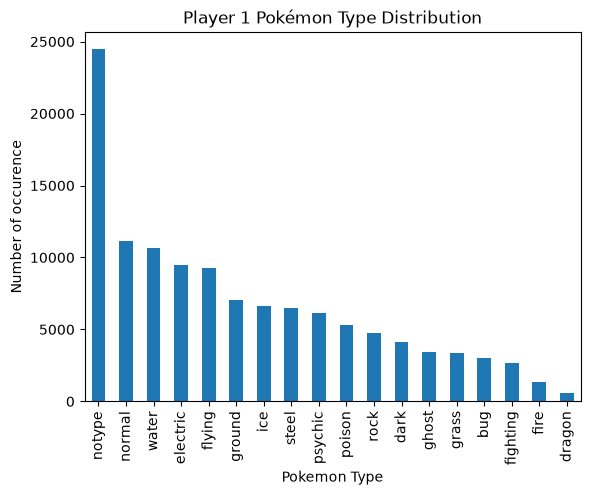

In [25]:
type_counts_train_df.plot(
    x = "Pokemon Type",
    y = "Count",
    kind = "bar", 
    legend=False
)

plt.ylabel("Number of occurence")
plt.title("Player 1 Pokémon Type Distribution")
plt.show()

In [26]:
# exploring base stats
stat_fields = [
    "base_hp",
    "base_atk",
    "base_def",
    "base_spa",
    "base_spd",
    "base_spe"
]

pokemon_rows = []

for battle in train_data:
    for pokemon in battle["p1_team_details"]:
        row = {}

        for field in stat_fields:
            row[field] = pokemon[field]

        pokemon_rows.append(row)

pokemon_df = pd.DataFrame(pokemon_rows)

In [27]:
pokemon_df[stat_fields].describe().round(1)

,base_hp,base_atk,base_def,base_spa,base_spd,base_spe
count,60000.0,60000.0,60000.0,60000.0,60000.0,60000.0
mean,91.8,90.6,96.1,85.0,84.2,71.1
std,38.4,23.3,42.3,28.9,22.8,29.1
min,10.0,5.0,5.0,10.0,20.0,5.0
25%,65.0,80.0,65.0,65.0,65.0,45.0
50%,90.0,90.0,85.0,85.0,85.0,70.0
75%,95.0,110.0,110.0,115.0,100.0,100.0
max,255.0,134.0,230.0,170.0,230.0,140.0


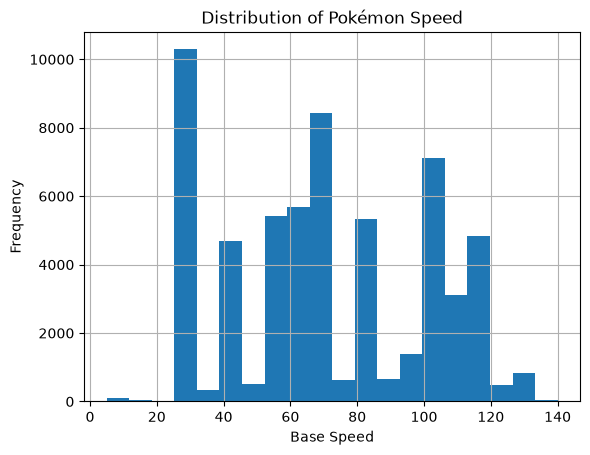

In [28]:
pokemon_df["base_spe"].hist(bins=20)

plt.xlabel("Base Speed")
plt.ylabel("Frequency")
plt.title("Distribution of Pokémon Speed")
plt.show()

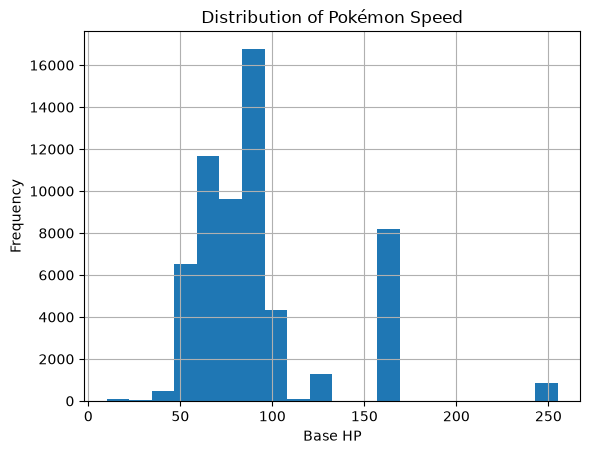

In [29]:
pokemon_df["base_hp"].hist(bins=20)

plt.xlabel("Base HP")
plt.ylabel("Frequency")
plt.title("Distribution of Pokémon Speed")
plt.show()

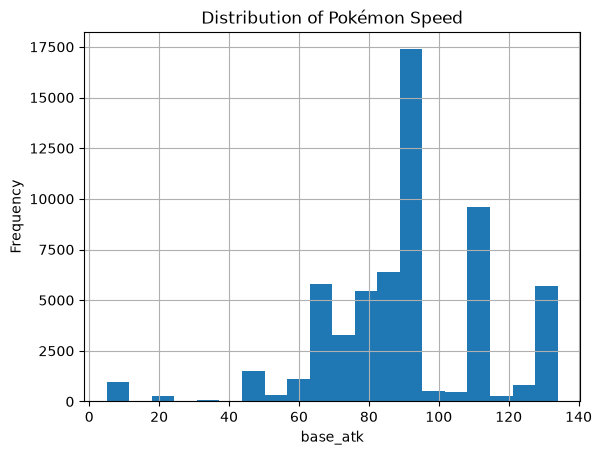

In [30]:
pokemon_df["base_atk"].hist(bins=20)

plt.xlabel("base_atk")
plt.ylabel("Frequency")
plt.title("Distribution of Pokémon Speed")
plt.show()

below: \
Compare Pokémon stats between wins and losses \
need to know if the characteristics of Player 1's teams differ depending on the battle outcome.

In [31]:

pokemon_rows = []

for battle in train_data:
    for pokemon in battle["p1_team_details"]:
        row = {"player_won": battle["player_won"]}

        for field in stat_fields:
            row[field] = pokemon[field]

        pokemon_rows.append(row)

pokemon_df = pd.DataFrame(pokemon_rows)

In [32]:
print(
    pokemon_df.groupby("player_won")[stat_fields]
    .mean()
    .round(1)
)

            base_hp  base_atk  base_def  base_spa  base_spd  base_spe
player_won                                                           
0              92.1      90.7      95.7      85.0      84.3      71.1
1              91.6      90.5      96.4      85.1      84.1      71.1


In [33]:
# Compare average team stats
team_rows = []

for battle in train_data:
    team = battle["p1_team_details"]

    row = {"player_won": battle["player_won"]}

    for field in stat_fields:
        row[field] = sum(
            pokemon[field] for pokemon in team
        ) / len(team)

    team_rows.append(row)

team_df = pd.DataFrame(team_rows)

print(
    team_df.groupby("player_won")[stat_fields]
    .mean()
    .round(1)
)

            base_hp  base_atk  base_def  base_spa  base_spd  base_spe
player_won                                                           
0              92.1      90.7      95.7      85.0      84.3      71.1
1              91.6      90.5      96.4      85.1      84.1      71.1


In [34]:
print(pokemon_df[stat_fields].agg(["min", "max"]).T)

          min  max
base_hp    10  255
base_atk    5  134
base_def    5  230
base_spa   10  170
base_spd   20  230
base_spe    5  140


#### **3.4 Explore the opponent's lead Pokémon**
Question: What information is available about the opponent, and how does it relate to battle outcomes?

In [35]:
# inspecting one opponent lead to understand the structure.
train_data[0]["p2_lead_details"]

{'name': 'forretress',
 'level': 100,
 'types': ['bug', 'steel'],
 'base_hp': 75,
 'base_atk': 90,
 'base_def': 140,
 'base_spa': 60,
 'base_spd': 60,
 'base_spe': 40}

In [36]:
# Count the types across all opponent leads
opponent_types_count = Counter()

for battle in train_data: 
    pokemon = battle["p2_lead_details"]

    for pokemon_type in pokemon["types"]:
        opponent_types_count[pokemon_type] += 1


# convert it into DataFrame
opponent_type_df = pd.DataFrame(
    opponent_types_count.most_common(),
    columns=["Pokemon Type", "Count"]
)

display(opponent_type_df)

,Pokemon Type,Count
0,notype,4444
1,electric,3271
2,normal,2172
3,flying,1809
4,psychic,1347
5,ice,1116
6,poison,1023
7,water,1005
8,grass,850
9,ground,802


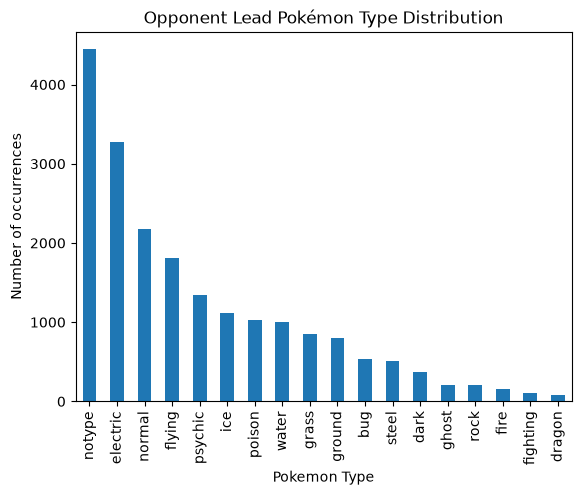

In [37]:
opponent_type_df.plot(
    x="Pokemon Type",
    y="Count",
    kind="bar",
    legend=False
)

plt.ylabel("Number of occurrences")
plt.title("Opponent Lead Pokémon Type Distribution")
plt.show()

In [38]:
# explore leads base stat

stat_fields = [
    "base_hp",
    "base_atk",
    "base_def",
    "base_spa",
    "base_spd",
    "base_spe"
]

opponent_rows = []

for battle in train_data:
    pokemon = battle["p2_lead_details"]

    row = {}

    for field in stat_fields:
        row[field] = pokemon[field]

    opponent_rows.append(row)

opponent_df = pd.DataFrame(opponent_rows)

In [39]:
display(opponent_df[stat_fields].describe().round(1))

,base_hp,base_atk,base_def,base_spa,base_spd,base_spe
count,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0
mean,95.5,88.7,84.1,93.9,86.7,76.2
std,36.5,20.9,34.3,28.2,21.4,30.8
min,20.0,5.0,5.0,10.0,30.0,5.0
25%,75.0,85.0,65.0,65.0,75.0,55.0
50%,90.0,90.0,77.0,95.0,90.0,85.0
75%,95.0,95.0,85.0,125.0,100.0,100.0
max,255.0,134.0,230.0,135.0,230.0,140.0


In [40]:
# Compare opponent lead characteristics between wins and losses

opponent_rows = []

for battle in train_data:
    pokemon = battle["p2_lead_details"]

    row = {"player_won": battle["player_won"]}

    for field in stat_fields:
        row[field] = pokemon[field]

    opponent_rows.append(row)

opponent_df = pd.DataFrame(opponent_rows)

In [41]:
opponent_stats_by_outcome = (
    opponent_df.groupby("player_won")[stat_fields]
    .mean()
    .round(1)
)

display(opponent_stats_by_outcome)

,base_hp,base_atk,base_def,base_spa,base_spd,base_spe
player_won,,,,,,
0,95.2,88.6,83.7,94.1,86.9,76.5
1,95.8,88.9,84.5,93.7,86.5,76.0


In [42]:
for outcome in [0, 1]:
    type_counts = Counter()

    for battle in train_data:
        if battle["player_won"] == outcome:
            for pokemon_type in battle["p2_lead_details"]["types"]:
                type_counts[pokemon_type] += 1

    print(f"\nPlayer 1 {'won' if outcome == 1 else 'lost'}:")
    print(type_counts.most_common())


Player 1 lost:
[('notype', 2215), ('electric', 1675), ('normal', 1073), ('flying', 915), ('psychic', 682), ('ice', 580), ('poison', 519), ('water', 500), ('grass', 408), ('ground', 402), ('bug', 265), ('steel', 242), ('dark', 190), ('ghost', 104), ('rock', 93), ('fire', 69), ('fighting', 40), ('dragon', 28)]

Player 1 won:
[('notype', 2229), ('electric', 1596), ('normal', 1099), ('flying', 894), ('psychic', 665), ('ice', 536), ('water', 505), ('poison', 504), ('grass', 442), ('ground', 400), ('bug', 274), ('steel', 271), ('dark', 175), ('rock', 110), ('ghost', 109), ('fire', 82), ('fighting', 62), ('dragon', 47)]


#### 3.5. Explore the battle timelines

In [43]:
battle = train_data[0]

print("Battle ID:", battle["battle_id"])
print("Player won:", battle["player_won"])
print("Number of timeline events:", len(battle["battle_timeline"]))

Battle ID: 0
Player won: 0
Number of timeline events: 30


In [44]:
battle["battle_timeline"][0]

{'turn': 1,
 'p1_pokemon_state': {'name': 'tyranitar',
  'hp_pct': 1.0,
  'status': 'nostatus',
  'effects': ['noeffect'],
  'boosts': {'atk': 0, 'def': 0, 'spa': 0, 'spd': 0, 'spe': 0}},
 'p1_move_details': {'name': 'earthquake',
  'type': 'ground',
  'category': 'physical',
  'base_power': 100,
  'accuracy': 1.0,
  'priority': 0},
 'p2_pokemon_state': {'name': 'forretress',
  'hp_pct': 0.86,
  'status': 'nostatus',
  'effects': ['noeffect'],
  'boosts': {'atk': 0, 'def': 0, 'spa': 0, 'spd': 0, 'spe': 0}},
 'p2_move_details': {'name': 'toxic',
  'type': 'poison',
  'category': 'status',
  'base_power': 0,
  'accuracy': 0.85,
  'priority': 0}}

In [45]:
battle["battle_timeline"][0].keys()

dict_keys(['turn', 'p1_pokemon_state', 'p1_move_details', 'p2_pokemon_state', 'p2_move_details'])

In [46]:
for event in battle["battle_timeline"][:3]:
    print(event)
    print("-" * 50)

{'turn': 1, 'p1_pokemon_state': {'name': 'tyranitar', 'hp_pct': 1.0, 'status': 'nostatus', 'effects': ['noeffect'], 'boosts': {'atk': 0, 'def': 0, 'spa': 0, 'spd': 0, 'spe': 0}}, 'p1_move_details': {'name': 'earthquake', 'type': 'ground', 'category': 'physical', 'base_power': 100, 'accuracy': 1.0, 'priority': 0}, 'p2_pokemon_state': {'name': 'forretress', 'hp_pct': 0.86, 'status': 'nostatus', 'effects': ['noeffect'], 'boosts': {'atk': 0, 'def': 0, 'spa': 0, 'spd': 0, 'spe': 0}}, 'p2_move_details': {'name': 'toxic', 'type': 'poison', 'category': 'status', 'base_power': 0, 'accuracy': 0.85, 'priority': 0}}
--------------------------------------------------
{'turn': 2, 'p1_pokemon_state': {'name': 'typhlosion', 'hp_pct': 1.0, 'status': 'tox', 'effects': ['noeffect'], 'boosts': {'atk': 0, 'def': 0, 'spa': 0, 'spd': 0, 'spe': 0}}, 'p1_move_details': None, 'p2_pokemon_state': {'name': 'forretress', 'hp_pct': 0.93, 'status': 'nostatus', 'effects': ['noeffect'], 'boosts': {'atk': 0, 'def': 0, 

In [47]:
battle = train_data[0]
timeline = battle["battle_timeline"]

turn_numbers = set(
    event["turn"]
    for event in timeline
    if "turn" in event
)

print("Number of events:", len(timeline))
print("Distinct turns:", len(turn_numbers))
print("Turn numbers:", sorted(turn_numbers))

Number of events: 30
Distinct turns: 30
Turn numbers: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]


In [48]:
event = train_data[0]["battle_timeline"][0]

print("Player 1 state:")
print(event["p1_pokemon_state"])

print("Player 2 state:")
print(event["p2_pokemon_state"])

Player 1 state:
{'name': 'tyranitar', 'hp_pct': 1.0, 'status': 'nostatus', 'effects': ['noeffect'], 'boosts': {'atk': 0, 'def': 0, 'spa': 0, 'spd': 0, 'spe': 0}}
Player 2 state:
{'name': 'forretress', 'hp_pct': 0.86, 'status': 'nostatus', 'effects': ['noeffect'], 'boosts': {'atk': 0, 'def': 0, 'spa': 0, 'spd': 0, 'spe': 0}}


In [49]:
for event in train_data[0]["battle_timeline"][:5]:
    print(
        "Turn:", event.get("turn"),
        "P1 state:", event.get("p1_pokemon_state"),
        "P2 state:", event.get("p2_pokemon_state")
    )

Turn: 1 P1 state: {'name': 'tyranitar', 'hp_pct': 1.0, 'status': 'nostatus', 'effects': ['noeffect'], 'boosts': {'atk': 0, 'def': 0, 'spa': 0, 'spd': 0, 'spe': 0}} P2 state: {'name': 'forretress', 'hp_pct': 0.86, 'status': 'nostatus', 'effects': ['noeffect'], 'boosts': {'atk': 0, 'def': 0, 'spa': 0, 'spd': 0, 'spe': 0}}
Turn: 2 P1 state: {'name': 'typhlosion', 'hp_pct': 1.0, 'status': 'tox', 'effects': ['noeffect'], 'boosts': {'atk': 0, 'def': 0, 'spa': 0, 'spd': 0, 'spe': 0}} P2 state: {'name': 'forretress', 'hp_pct': 0.93, 'status': 'nostatus', 'effects': ['noeffect'], 'boosts': {'atk': 0, 'def': 0, 'spa': 0, 'spd': 0, 'spe': 0}}
Turn: 3 P1 state: {'name': 'typhlosion', 'hp_pct': 0.94, 'status': 'tox', 'effects': ['noeffect'], 'boosts': {'atk': 0, 'def': 0, 'spa': 0, 'spd': 0, 'spe': 0}} P2 state: {'name': 'zapdos', 'hp_pct': 0.61, 'status': 'nostatus', 'effects': ['noeffect'], 'boosts': {'atk': 0, 'def': 0, 'spa': 0, 'spd': 0, 'spe': 0}}
Turn: 4 P1 state: {'name': 'typhlosion', 'hp_

In [50]:
for event in train_data[0]["battle_timeline"][:5]:
    print("Turn:", event.get("turn"))
    print("P1 move:", event.get("p1_move_details"))
    print("P2 move:", event.get("p2_move_details"))
    print("-" * 40)

Turn: 1
P1 move: {'name': 'earthquake', 'type': 'ground', 'category': 'physical', 'base_power': 100, 'accuracy': 1.0, 'priority': 0}
P2 move: {'name': 'toxic', 'type': 'poison', 'category': 'status', 'base_power': 0, 'accuracy': 0.85, 'priority': 0}
----------------------------------------
Turn: 2
P1 move: None
P2 move: {'name': 'toxic', 'type': 'poison', 'category': 'status', 'base_power': 0, 'accuracy': 0.85, 'priority': 0}
----------------------------------------
Turn: 3
P1 move: {'name': 'fireblast', 'type': 'fire', 'category': 'special', 'base_power': 120, 'accuracy': 0.85, 'priority': 0}
P2 move: None
----------------------------------------
Turn: 4
P1 move: {'name': 'fireblast', 'type': 'fire', 'category': 'special', 'base_power': 120, 'accuracy': 0.85, 'priority': 0}
P2 move: {'name': 'hiddenpower', 'type': 'normal', 'category': 'physical', 'base_power': 0, 'accuracy': 1.0, 'priority': 0}
----------------------------------------
Turn: 5
P1 move: {'name': 'rest', 'type': 'psychi

#### 3.6. Understand the type chart
Question: How does the type chart represent type effectiveness?

In [51]:
# Step 1 — Check the structure
print(type_chart.shape)
print(type_chart.info())

(110, 3)
<class 'pandas.DataFrame'>
RangeIndex: 110 entries, 0 to 109
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   attacking_type  110 non-null    str    
 1   defending_type  110 non-null    str    
 2   multiplier      110 non-null    float64
dtypes: float64(1), str(2)
memory usage: 2.7 KB
None


In [52]:
# Count unique attacking and defending types
print("Unique attacking types:",
      type_chart["attacking_type"].nunique())

print("Unique defending types:",
      type_chart["defending_type"].nunique())

Unique attacking types: 17
Unique defending types: 17


In [53]:
# Inspect the effectiveness multipliers
print(sorted(type_chart["multiplier"].unique()))

[np.float64(0.0), np.float64(0.5), np.float64(2.0)]


In [54]:
# Check for duplicate and missing combinations
print(
    "Duplicate combinations:",
    type_chart.duplicated(
        subset=["attacking_type", "defending_type"]
    ).sum()
)

Duplicate combinations: 0


In [55]:
# check whether any multiplier values are missing:
print(type_chart.isnull().sum())

attacking_type    0
defending_type    0
multiplier        0
dtype: int64


In [56]:
attacking_types = type_chart["attacking_type"].unique()
defending_types = type_chart["defending_type"].unique()

expected_combinations = len(attacking_types) * len(defending_types)
actual_combinations = type_chart[
    ["attacking_type", "defending_type"]
].drop_duplicates().shape[0]

print("Expected combinations:", expected_combinations)
print("Actual combinations:", actual_combinations)
print("Missing combinations:", expected_combinations - actual_combinations)

Expected combinations: 289
Actual combinations: 110
Missing combinations: 179


**The sunnary:**

- Target: It has 5,000 wins and 5,000 losses, so it is balanced. A model that always predicts one class would get 50% accuracy.
- Player 1’s team: You counted Pokémon types and summarized base stats. The average stats are very similar for wins and losses, so team averages alone may not tell much about the outcome. That doesn’t rule out their usefulness alongside other features.
- Opponent’s lead: You inspected its types and stats and compared them by outcome. The averages and type counts look broadly similar between wins and losses.
- Timeline: You confirmed it contains turn-by-turn Pokémon states and moves. Those details may be informative, but they describe how the battle unfolded.
- Type chart: It has 110 listed pairs out of 289 possible pairs, with no duplicate pairs or missing values among the rows. The meaning of the 179 unlisted pairs is still unknown; don’t assume they mean neutral matchups.
One small notebook detail: the three histograms for Speed, HP, and Attack currently all have the title “Distribution of Pokémon Speed.” 
> note: to correct the titles when you revisit Phase 3.

----

Side note: \ 
Three findings worth recording
1. The target is balanced. Your training data has 5,000 wins and 5,000 losses. A majority-class baseline therefore achieves 50% accuracy.

2. Your initial team statistics show little difference between outcomes. For example, the mean base Speed of Player 1's Pokémon is 71.1 for both winning and losing battles. This suggests that simple average statistics may have limited predictive power on their own. It does not mean they are useless.

3. The type chart has 110 combinations, not 289. Your code correctly identifies 179 missing combinations out of the \(17 \times 17 = 289\) possible pairs. This needs attention before you use the chart in features. The missing combinations might be intentional, so don't automatically treat them as errors or as neutral effectiveness.

----

### Phase 4 — Feature Engineering
Goal: Transform raw Pokémon battle data into numerical features that a machine learning model can use. -> keeping player_won separate as the answer the model learns to predict.

#### 4.1. Define the input and output

- Input: One battle represented by a nested dictionary.
- Output: One row containing numerical or encoded features describing that battle.
- Target: player_won, kept separately from the features. 

For example, a raw Pokémon record might contain base_spe = 61. Your feature extraction could use that value directly or calculate a team-level statistic from it.

#### 4.2. Player 1's team statistics
For each of the six base stats, calculate a team average.

In [57]:
# Calculate the average of all six stats
stat_fields = [
    "base_hp",
    "base_atk",
    "base_def",
    "base_spa",
    "base_spd",
    "base_spe"
]

battle = train_data[0]
team = battle["p1_team_details"]

row = {}

for field in stat_fields:
    total = 0

    for pokemon in team:
        total = total + pokemon[field]

    row[field + "_mean"] = total / len(team)

row

{'base_hp_mean': 83.0,
 'base_atk_mean': 88.0,
 'base_def_mean': 91.33333333333333,
 'base_spa_mean': 94.83333333333333,
 'base_spd_mean': 94.16666666666667,
 'base_spe_mean': 84.33333333333333}

In [58]:
# Repeat for every battle
team_rows = []

for battle in train_data:
    team = battle["p1_team_details"]

    row = {
        "battle_id": battle["battle_id"],
        "player_won": battle["player_won"]
    }

    for field in stat_fields:
        total = 0

        for pokemon in team:
            total = total + pokemon[field]

        row[field + "_mean"] = total / len(team)

    team_rows.append(row)

In [59]:
team_features_df = pd.DataFrame(team_rows)

display(team_features_df.head())

,battle_id,player_won,base_hp_mean,base_atk_mean,base_def_mean,base_spa_mean,base_spd_mean,base_spe_mean
0,0,0,83.000000,88.000000,91.333333,94.833333,94.166667,84.333333
1,1,0,91.666667,83.333333,99.166667,75.833333,90.000000,70.833333
2,2,0,95.000000,113.166667,97.500000,77.500000,89.166667,69.333333
3,3,0,119.166667,75.000000,98.333333,75.000000,96.666667,65.000000
4,4,0,105.166667,89.500000,95.333333,94.166667,83.333333,60.833333


In [60]:
# Check whether winning teams have different stats
feature_columns = [
    field + "_mean"
    for field in stat_fields
]

display(
    team_features_df.groupby("player_won")[feature_columns]
    .mean()
    .round(2)
)

,base_hp_mean,base_atk_mean,base_def_mean,base_spa_mean,base_spd_mean,base_spe_mean
player_won,,,,,,
0,92.10,90.69,95.67,84.99,84.34,71.08
1,91.57,90.50,96.44,85.11,84.14,71.12


In [61]:
team_features_df.agg(["min", "max"]).T

,min,max
battle_id,0.000000,9999.000000
player_won,0.000000,1.000000
base_hp_mean,32.166667,149.166667
base_atk_mean,37.666667,127.166667
base_def_mean,32.833333,138.333333
base_spa_mean,29.333333,122.333333
base_spd_mean,38.333333,130.000000
base_spe_mean,37.000000,115.833333


#### 4.3. Extract opponent lead statistics
Player 1: has six Pokémon, so we calculated the average of each stat across the team.

Player 2: have the lead Pokémon's details, so we use its individual stats directly. There is no averaging across a team.

In [62]:
stat_fields = [
    "base_hp",
    "base_atk",
    "base_def",
    "base_spa",
    "base_spd",
    "base_spe"
]

In [63]:
battle = train_data[0]

p2_lead = battle["p2_lead_details"]

for field in stat_fields:
    print(field, p2_lead[field])

base_hp 75
base_atk 90
base_def 140
base_spa 60
base_spd 60
base_spe 40


In [64]:
opponent_rows = []

for battle in train_data:
    p2_lead = battle["p2_lead_details"]

    row = {
        "battle_id": battle["battle_id"],
        "player_won": battle["player_won"]
    }

    for field in stat_fields:
        row["p2_lead_" + field.replace("base_", "")] = p2_lead[field]

    opponent_rows.append(row)

In [65]:
opponent_features_df = pd.DataFrame(opponent_rows)

display(opponent_features_df.head())

,battle_id,player_won,p2_lead_hp,p2_lead_atk,p2_lead_def,p2_lead_spa,p2_lead_spd,p2_lead_spe
0,0,0,75,90,140,60,60,40
1,1,0,90,85,75,115,100,115
2,2,0,95,95,85,125,65,55
3,3,0,50,95,180,85,45,70
4,4,0,90,90,85,125,90,100


In [66]:
p2_feature_columns = [
    "p2_lead_" + field.replace("base_", "")
    for field in stat_fields
]

display(
    opponent_features_df.groupby("player_won")[p2_feature_columns]
    .mean()
    .round(2)
)

,p2_lead_hp,p2_lead_atk,p2_lead_def,p2_lead_spa,p2_lead_spd,p2_lead_spe
player_won,,,,,,
0,95.17,88.58,83.69,94.14,86.93,76.45
1,95.81,88.87,84.53,93.66,86.50,76.04


#### 4.4. Pokémon type features

> "notype" appears frequently in dataset. Since it is a placeholder rather than a meaningful Pokémon type, we'll exclude it from type counts and encoding.

In [67]:
type_rows = []

for battle in train_data:
    team = battle["p1_team_details"]

    type_counts = Counter()

    for pokemon in team:
        for pokemon_type in pokemon["types"]:
            if pokemon_type != "notype":
                type_counts[pokemon_type] += 1

    row = {"battle_id": battle["battle_id"]}

    for pokemon_type, count in type_counts.items():
        row["p1_type_" + pokemon_type] = count

    type_rows.append(row)

In [68]:
type_rows

[{'battle_id': 0,
  'p1_type_dark': 2,
  'p1_type_rock': 2,
  'p1_type_fire': 1,
  'p1_type_ground': 1,
  'p1_type_psychic': 1,
  'p1_type_electric': 1},
 {'battle_id': 1,
  'p1_type_electric': 1,
  'p1_type_flying': 1,
  'p1_type_steel': 2,
  'p1_type_bug': 1,
  'p1_type_ghost': 1,
  'p1_type_normal': 1,
  'p1_type_water': 1},
 {'battle_id': 2,
  'p1_type_electric': 1,
  'p1_type_bug': 1,
  'p1_type_fighting': 2,
  'p1_type_dark': 1,
  'p1_type_rock': 1,
  'p1_type_ice': 1,
  'p1_type_water': 1,
  'p1_type_normal': 1},
 {'battle_id': 3,
  'p1_type_electric': 1,
  'p1_type_flying': 2,
  'p1_type_normal': 2,
  'p1_type_ice': 1,
  'p1_type_water': 1,
  'p1_type_steel': 1,
  'p1_type_dark': 1},
 {'battle_id': 4,
  'p1_type_ground': 2,
  'p1_type_poison': 1,
  'p1_type_grass': 1,
  'p1_type_psychic': 1,
  'p1_type_steel': 1,
  'p1_type_electric': 1,
  'p1_type_flying': 1,
  'p1_type_normal': 1,
  'p1_type_water': 1},
 {'battle_id': 5,
  'p1_type_grass': 1,
  'p1_type_psychic': 2,
  'p1_typ

In [69]:
p1_types_df = pd.DataFrame(type_rows).fillna(0)

display(p1_types_df.head())

,battle_id,p1_type_dark,p1_type_rock,p1_type_fire,p1_type_ground,p1_type_psychic,p1_type_electric,p1_type_flying,p1_type_steel,p1_type_bug,p1_type_ghost,p1_type_normal,p1_type_water,p1_type_fighting,p1_type_ice,p1_type_poison,p1_type_grass,p1_type_dragon
0,0,2.0,2.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,0.0,0.0,0.0,0.0,0.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
2,2,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,2.0,1.0,0.0,0.0,0.0
3,3,1.0,0.0,0.0,0.0,0.0,1.0,2.0,1.0,0.0,0.0,2.0,1.0,0.0,1.0,0.0,0.0,0.0
4,4,0.0,0.0,0.0,2.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0


**Note:**
Why fillna(0)?

Suppose one team contains Fire Pokémon but no Water Pokémon. The Water count is missing from the dictionary for that battle. When Pandas creates the table, it fills the absent entry with NaN. Replacing it with zero correctly indicates that the team has no Pokémon of that type.

Each row now represents one battle, and each type column represents its count in Player 1's team.

the opponent contributes only one Pokémon. We can use binary features: 1 if the lead has a particular type, and 0 otherwise.

In [70]:
opponent_type_rows = []

for battle in train_data:
    pokemon = battle["p2_lead_details"]

    row = {"battle_id": battle["battle_id"]}

    for pokemon_type in pokemon["types"]:
        if pokemon_type != "notype":
            row["p2_lead_type_" + pokemon_type] = 1

    opponent_type_rows.append(row)

p2_types_df = pd.DataFrame(opponent_type_rows).fillna(0)

display(p2_types_df.head())

,battle_id,p2_lead_type_bug,p2_lead_type_steel,p2_lead_type_electric,p2_lead_type_grass,p2_lead_type_psychic,p2_lead_type_ice,p2_lead_type_water,p2_lead_type_flying,p2_lead_type_normal,p2_lead_type_dark,p2_lead_type_ground,p2_lead_type_poison,p2_lead_type_dragon,p2_lead_type_ghost,p2_lead_type_fire,p2_lead_type_rock,p2_lead_type_fighting
0,0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,3,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [71]:
print("Player 1 type features:", p1_types_df.shape)
print("Opponent lead type features:", p2_types_df.shape)

print(p1_types_df.isnull().sum().sum())
print(p2_types_df.isnull().sum().sum())

Player 1 type features: (10000, 18)
Opponent lead type features: (10000, 18)
0
0


#### 4.4. Type matchup features

chart has three columns:
- attacking_type: the type of the move.
- defending_type: the type of the Pokémon receiving the move.
- multiplier: the damage multiplier for that interaction.

For example, if a Fire-type move attacks a Grass-type Pokémon and the multiplier is 2.0, the move deals double damage.

In [72]:
# Build a lookup dictionary
type_effectiveness = {}

for _, row in type_chart.iterrows():
    key = (row["attacking_type"], row["defending_type"])
    type_effectiveness[key] = row["multiplier"]

In [73]:
# For example, to check Fire against Grass:
print(type_effectiveness.get(("fire", "grass")))

2.0


In [74]:
# Inspect the opponent lead's types 
battle = train_data[0]

p1_team = battle["p1_team_details"]
p2_lead = battle["p2_lead_details"]

p2_types = [
    t for t in p2_lead["types"]
    if t != "notype"
]

print("Player 1 team:")
for pokemon in p1_team:
    print(pokemon["name"], pokemon["types"])

print("Opponent lead:", p2_lead["name"], p2_types)

Player 1 team:
tyranitar ['dark', 'rock']
typhlosion ['fire', 'notype']
golem ['ground', 'rock']
umbreon ['dark', 'notype']
alakazam ['notype', 'psychic']
raikou ['electric', 'notype']
Opponent lead: forretress ['bug', 'steel']


In [75]:
# Count known advantages and disadvantages
def matchup_category(pokemon, opponent_types):
    attacking_types = [
        t for t in pokemon["types"]
        if t != "notype"
    ]

    # No meaningful attacking type to compare
    if not attacking_types or not opponent_types:
        return "unknown"

    multipliers = []

    for attack_type in attacking_types:
        for defense_type in opponent_types:
            key = (attack_type, defense_type)

            multiplier = type_effectiveness.get(key, 1.0)
            multipliers.append(multiplier)

    # Combine effectiveness against a dual-type opponent
    combined = 1.0

    for multiplier in multipliers:
        combined *= multiplier

    if combined > 1:
        return "advantage"
    elif combined < 1:
        return "disadvantage"
    else:
        return "neutral"

In [76]:
# count the categories for one battle:
categories = Counter(
    matchup_category(pokemon, p2_types)
    for pokemon in p1_team
)
# The counts should add up to six, because Player 1 has six Pokémon.
print(categories)

# > It does not account for the Pokémon's actual moves, their damage, or battle conditions.

Counter({'disadvantage': 3, 'neutral': 2, 'advantage': 1})


In [77]:
# Create matchup features for every battle
matchup_rows = []

for battle in train_data:
    p1_team = battle["p1_team_details"]
    p2_lead = battle["p2_lead_details"]

    p2_types = [
        t for t in p2_lead["types"]
        if t != "notype"
    ]

    categories = Counter(
        matchup_category(pokemon, p2_types)
        for pokemon in p1_team
    )

    row = {
        "battle_id": battle["battle_id"],
        "p1_advantage_count": categories["advantage"],
        "p1_disadvantage_count": categories["disadvantage"],
        "p1_neutral_count": categories["neutral"],
    }

    matchup_rows.append(row)

matchup_features_df = pd.DataFrame(matchup_rows)

display(matchup_features_df.head())

,battle_id,p1_advantage_count,p1_disadvantage_count,p1_neutral_count
0,0,1,3,2
1,1,0,3,3
2,2,2,2,2
3,3,1,1,4
4,4,0,4,2


**Note on missing type combinations:** The type chart contains only 110 of 289 possible attacking/defending type combinations. Since the dataset does not specify how to handle unlisted pairs, I will assume their effectiveness multiplier is 1.0 (neutral). This assumption will be used when calculating combined type effectiveness and should be revisited if more information becomes available.

#### 4.5. Pokémon item features

In [78]:
# Inspect the item field
battle = train_data[0]
pokemon = battle["p1_team_details"][0]

print("the keys: ", pokemon.keys())
print("the item: ", pokemon.get("item"))

the keys:  dict_keys(['name', 'level', 'types', 'base_hp', 'base_atk', 'base_def', 'base_spa', 'base_spd', 'base_spe', 'item'])
the item:  leftovers


In [79]:
# Check item values across the dataset
from collections import Counter

item_counts = Counter()

for battle in train_data:
    for pokemon in battle["p1_team_details"]:
        item_counts[pokemon.get("item")] += 1

item_counts.most_common(20)

[('leftovers', 57329),
 ('thickclub', 1057),
 ('miracleberry', 750),
 ('mintberry', 210),
 ('charcoal', 104),
 ('goldberry', 102),
 ('lightball', 75),
 ('berryjuice', 65),
 ('berserkgene', 37),
 ('przcureberry', 33),
 ('berry', 31),
 ('scopelens', 20),
 ('quickclaw', 17),
 ('brightpowder', 13),
 ('blackbelt', 11),
 ('stick', 10),
 ('focusband', 10),
 ('magnet', 10),
 ('oranberry', 9),
 ('pinkbow', 9)]

In [80]:
item_rows = []

for battle in train_data:
    team = battle["p1_team_details"]

    item_counts = Counter()

    for pokemon in team:
        item_counts[pokemon["item"]] += 1

    row = {"battle_id": battle["battle_id"]}

    for item, count in item_counts.items():
        row["p1_item_" + item] = count

    item_rows.append(row)

In [81]:
p1_items_df = pd.DataFrame(item_rows).fillna(0)

display(p1_items_df.head())

,battle_id,p1_item_leftovers,p1_item_mintberry,p1_item_berserkgene,p1_item_miracleberry,p1_item_thickclub,p1_item_goldberry,p1_item_charcoal,p1_item_lightball,p1_item_berryjuice,...,p1_item_metalcoat,p1_item_mysteryberry,p1_item_twistedspoon,p1_item_polkadotbow,p1_item_blackglasses,p1_item_bitterberry,p1_item_gengarite,p1_item_psncureberry,p1_item_luckypunch,p1_item_dragonfang
0,0,4.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,6.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2,6.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,3,6.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,6.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [82]:
print("Shape:", p1_items_df.shape)
print("Missing values:", p1_items_df.isnull().sum().sum())
print("Number of item features:", p1_items_df.shape[1] - 1)

Shape: (10000, 48)
Missing values: 0
Number of item features: 47


In [83]:
item_feature_columns = [
    col for col in p1_items_df.columns
    if col.startswith("p1_item_")
]

item_totals = p1_items_df[item_feature_columns].sum().sort_values()

print("Least common items:")
print(item_totals.head(10))

print("\nMost common items:")
print(item_totals.tail(10))

Least common items:
p1_item_pokeball        1.0
p1_item_luckypunch      1.0
p1_item_twistedspoon    2.0
p1_item_gengarite       2.0
p1_item_chestoberry     2.0
p1_item_metalcoat       2.0
p1_item_dragonfang      2.0
p1_item_mysteryberry    2.0
p1_item_nevermeltice    2.0
p1_item_psncureberry    2.0
dtype: float64

Most common items:
p1_item_przcureberry       33.0
p1_item_berserkgene        37.0
p1_item_berryjuice         65.0
p1_item_lightball          75.0
p1_item_goldberry         102.0
p1_item_charcoal          104.0
p1_item_mintberry         210.0
p1_item_miracleberry      750.0
p1_item_thickclub        1057.0
p1_item_leftovers       57329.0
dtype: float64


In [84]:
item_battle_counts = (
    p1_items_df[item_feature_columns] > 0
).sum().sort_values()

print("Items appearing in the fewest battles:")
print(item_battle_counts.head(10))

print("\nItems appearing in the most battles:")
print(item_battle_counts.tail(10))

Items appearing in the fewest battles:
p1_item_pokeball        1
p1_item_luckypunch      1
p1_item_twistedspoon    2
p1_item_gengarite       2
p1_item_chestoberry     2
p1_item_metalcoat       2
p1_item_dragonfang      2
p1_item_mysteryberry    2
p1_item_nevermeltice    2
p1_item_psncureberry    2
dtype: int64

Items appearing in the most battles:
p1_item_berryjuice        31
p1_item_przcureberry      32
p1_item_berserkgene       34
p1_item_goldberry         69
p1_item_lightball         75
p1_item_charcoal         104
p1_item_mintberry        205
p1_item_miracleberry     642
p1_item_thickclub       1056
p1_item_leftovers       9993
dtype: int64


**Note:** We have 47 item features, so we investigate how frequently each item appears across battles to identify rare and common items.

The results show that item frequencies vary considerably. Some items appear in only 1–2 battles, while `leftovers` appears in 9,993 battles.

Since we are still in the feature engineering stage, we will keep all 47 item features for now. Removing features before evaluating their predictive usefulness could discard useful information. We can reconsider rare or uninformative features during model evaluation.


#### 4.6. Build and inspect the feature table

WE've already created separate DataFrames for:
- `team_features_df` — Player 1's six team-average stats.
- `opponent_features_df` — the opponent lead's six base stats.
- `p1_types_df` — counts of types in Player 1's team.
- `p2_types_df` — the opponent lead's type indicators.
- `matchup_features_df` — type matchup counts.
- `p1_items_df` — Player 1's item features.

The main goal now is to combine these into one feature table 

We'll also keep `battle_id` temporarily to identify battles, but it will not be used as a model feature. The target `player_won` will be extracted separately into `y_train`.

In [85]:
# Start with Player 1's team statistics
train_features = team_features_df.copy()

# Add opponent statistics
train_features = train_features.merge(
    opponent_features_df.drop(columns=["player_won"]),
    on="battle_id"
)

# Add type features
train_features = train_features.merge(
    p1_types_df, on="battle_id"
)

train_features = train_features.merge(
    p2_types_df, on="battle_id"
)

# Add matchup features
train_features = train_features.merge(
    matchup_features_df, on="battle_id"
)

# Add item features
train_features = train_features.merge(
    p1_items_df, on="battle_id"
)

display(train_features.head())
print("Shape:", train_features.shape)

,battle_id,player_won,base_hp_mean,base_atk_mean,base_def_mean,base_spa_mean,base_spd_mean,base_spe_mean,p2_lead_hp,p2_lead_atk,...,p1_item_metalcoat,p1_item_mysteryberry,p1_item_twistedspoon,p1_item_polkadotbow,p1_item_blackglasses,p1_item_bitterberry,p1_item_gengarite,p1_item_psncureberry,p1_item_luckypunch,p1_item_dragonfang
0,0,0,83.000000,88.000000,91.333333,94.833333,94.166667,84.333333,75,90,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,0,91.666667,83.333333,99.166667,75.833333,90.000000,70.833333,90,85,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2,0,95.000000,113.166667,97.500000,77.500000,89.166667,69.333333,95,95,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,3,0,119.166667,75.000000,98.333333,75.000000,96.666667,65.000000,50,95,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,0,105.166667,89.500000,95.333333,94.166667,83.333333,60.833333,90,90,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Shape: (10000, 98)


In [86]:
y_train = train_features["player_won"]

X_train = train_features.drop(
    columns=["battle_id", "player_won"]
)

**Create the test feature DataFrames**

In [87]:
# Player 1's team statistics
test_team_rows = []

for battle in test_data:
    team = battle["p1_team_details"]

    row = {"battle_id": battle["battle_id"]}

    for field in stat_fields:
        total = 0

        for pokemon in team:
            total += pokemon[field]

        row[field + "_mean"] = total / len(team)

    test_team_rows.append(row)

test_team_features_df = pd.DataFrame(test_team_rows).fillna(0)

In [88]:
# Opponent lead statistics
test_opponent_rows = []

for battle in test_data:
    p2_lead = battle["p2_lead_details"]

    row = {"battle_id": battle["battle_id"]}

    for field in stat_fields:
        name = field.replace("base_", "")
        row["p2_lead_" + name] = p2_lead[field]

    test_opponent_rows.append(row)

test_opponent_features_df = pd.DataFrame(test_opponent_rows).fillna(0)

In [89]:
# Player 1's type features
test_type_rows = []

for battle in test_data:
    row = {"battle_id": battle["battle_id"]}
    type_counts = Counter()

    for pokemon in battle["p1_team_details"]:
        for pokemon_type in pokemon["types"]:
            if pokemon_type != "notype":
                type_counts[pokemon_type] += 1

    for pokemon_type, count in type_counts.items():
        row["p1_type_" + pokemon_type] = type_counts[pokemon_type]

    test_type_rows.append(row)

test_p1_types_df = pd.DataFrame(test_type_rows).fillna(0)

In [90]:
# Opponent lead type features
test_opponent_type_rows = []

for battle in test_data:
    pokemon = battle["p2_lead_details"]

    row = {"battle_id": battle["battle_id"]}

    for pokemon_type, count in type_counts.items():
        row["p2_lead_type_" + pokemon_type] = int(
            pokemon_type in pokemon["types"]
        )

    test_opponent_type_rows.append(row)

test_p2_types_df = pd.DataFrame(test_opponent_type_rows).fillna(0)

In [91]:
# Type matchup features

test_matchup_rows = []

for battle in test_data:
    team = battle["p1_team_details"]
    opponent = battle["p2_lead_details"]

    opponent_types = [
        t for t in opponent["types"] if t != "notype"
    ]

    categories = Counter(
        matchup_category(pokemon, opponent_types)
        for pokemon in team
    )

    row = {
        "battle_id": battle["battle_id"],
        "p1_advantage_count": categories["advantage"],
        "p1_disadvantage_count": categories["disadvantage"],
        "p1_neutral_count": categories["neutral"]
    }

    test_matchup_rows.append(row)

test_matchup_features_df = pd.DataFrame(test_matchup_rows).fillna(0)

In [92]:
# Player 1's item features
test_item_rows = []

for battle in test_data:
    item_counts = Counter(
        pokemon["item"]
        for pokemon in battle["p1_team_details"]
        if pokemon.get("item") is not None
    )

    row = {"battle_id": battle["battle_id"]}

    for item, count in item_counts.items():
        row["p1_item_" + item] = item_counts[item]

    test_item_rows.append(row)

test_p1_items_df = pd.DataFrame(test_item_rows).fillna(0)

In [93]:
test_features = test_team_features_df.copy()

test_features = test_features.merge(
    test_opponent_features_df, on="battle_id"
)

test_features = test_features.merge(
    test_p1_types_df, on="battle_id"
)

test_features = test_features.merge(
    test_p2_types_df, on="battle_id"
)

test_features = test_features.merge(
    test_matchup_features_df, on="battle_id"
)

test_features = test_features.merge(
    test_p1_items_df, on="battle_id"
)

In [94]:
X_test = test_features.drop(columns=["battle_id"])

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

---------------

#### Phase 5 — Data Preparation and Validation
Goal: Verify that the feature tables created in Phase 4 are correct, consistent, and ready for machine learning.

In [95]:
checks = {
    "Correct training rows": len(X_train) == 10000,
    "Correct target length": len(y_train) == 10000,
    "Correct test rows": len(X_test) == 5000,
    "Train/test columns match": X_train.columns.equals(X_test.columns),
    "No target in features": "player_won" not in X_train.columns,
    "No ID in features": "battle_id" not in X_train.columns,
    "No missing training values": not X_train.isnull().any().any(),
    "No missing test values": not X_test.isnull().any().any(),
    "Only binary target labels": set(y_train.unique()).issubset({0, 1}),
}

for check, passed in checks.items():
    print(f"{'PASS' if passed else 'CHECK'}: {check}")

PASS: Correct training rows
PASS: Correct target length
PASS: Correct test rows
PASS: Train/test columns match
PASS: No target in features
PASS: No ID in features
PASS: No missing training values
PASS: No missing test values
PASS: Only binary target labels


--------------------

#### Phase 6 — Baseline Model

In [96]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

# Split the labeled data into training and validation parts
X_train_part, X_validation, y_train_part, y_validation = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Create and train the baseline model
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train_part, y_train_part)

# Predict the validation labels
dummy_predictions = dummy_model.predict(X_validation)

# Measure accuracy
dummy_accuracy = accuracy_score(y_validation, dummy_predictions)
print("Dummy classifier accuracy:", dummy_accuracy)

Dummy classifier accuracy: 0.5


A baseline gives us a simple reference score to compare with later models. The DummyClassifier does not use Pokémon features; it always predicts the most frequent class. Its validation accuracy was 50%. Later models will be evaluated on the same validation split, and their accuracy can be compared with this result.

_____ 

#### Phase 7 — First ML Model: Train Logistic Regression

Logistic Regression is our first model that uses the Pokémon features to predict the battle outcome. We train it on the training portion of the split and evaluate it on the same validation portion used for the DummyClassifier. We scale the numerical features because Logistic Regression can be affected by differences in feature scales. The scaler is fitted only on the training portion.

In [97]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

# Scale features, then train Logistic Regression
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

logistic_model.fit(X_train_part, y_train_part)

# Predict outcomes for validation battles
logistic_predictions = logistic_model.predict(X_validation)

# Evaluate the model
logistic_accuracy = accuracy_score(
    y_validation, logistic_predictions
)

print("Dummy classifier accuracy:", dummy_accuracy)
print("Logistic Regression accuracy:", logistic_accuracy)

# Rows = actual labels; columns = predicted labels
print("Confusion matrix:")
print(confusion_matrix(
    y_validation, logistic_predictions, labels=[0, 1]
))

Dummy classifier accuracy: 0.5
Logistic Regression accuracy: 0.54
Confusion matrix:
[[510 490]
 [430 570]]


**Phase 7 results**

- Logistic Regression validation accuracy: **54%**.
- DummyClassifier baseline accuracy: **50%**.
- Logistic Regression improved by **4 percentage points** on this validation split.
- Confusion matrix (actual rows and predicted columns, labels 0 then 1): of 1,000 actual losses, 510 were correctly predicted as losses and 490 were predicted as wins. Of 1,000 actual wins, 570 were correctly predicted as wins and 430 were predicted as losses.
- Limitation: this result comes from one train/validation split, so performance may vary with a different split and may not represent performance on unseen competition data.

#### Phase 8 — Model Evaluation and Interpretation

Accuracy gives the overall share of correct predictions, but it does not show which class the model handles better. We will examine precision, recall, and F1-score for each outcome. Then we will inspect the Logistic Regression coefficients to see which features are associated with predicting a win or a loss. These associations do not prove cause and effect.

In [98]:
from sklearn.metrics import classification_report

# Show precision, recall, and F1-score for losses (0) and wins (1)
print(classification_report(
    y_validation,
    logistic_predictions,
    labels=[0, 1],
    target_names=["Loss (0)", "Win (1)"],
    zero_division=0
))

              precision    recall  f1-score   support

    Loss (0)       0.54      0.51      0.53      1000
     Win (1)       0.54      0.57      0.55      1000

    accuracy                           0.54      2000
   macro avg       0.54      0.54      0.54      2000
weighted avg       0.54      0.54      0.54      2000



Results:

- Loss (0): Precision = 0.54, Recall = 0.51, F1-score = 0.53.
- Win (1): Precision = 0.54, Recall = 0.57, F1-score = 0.55.
- Overall accuracy: 54%.
- Macro average F1-score: 0.54.

Interpretation:

Precision measures how many predictions for a class were correct.

Recall measures how many actual cases of a class the model correctly identified.

F1-score balances precision and recall.

The model identifies wins slightly better than losses, with a recall of 57% for wins compared to 51% for losses.

Overall, the metrics show modest predictive performance, improving on the 50% DummyClassifier baseline.

#### Phase 9 — Model Improvement

#### 9.1. Current benchmark

The DummyClassifier achieved 50% holdout accuracy, and Logistic Regression achieved 54% holdout accuracy. Both scores use the same existing validation split. We will use them as reference points for the models in this phase.

#### 9.2. Five-fold cross-validation for Logistic Regression

In 5-fold cross-validation, the training partition is divided into five parts. The model trains on four parts and is scored on the remaining part; this repeats until each part has been used for validation once. The five scores show how performance varies across different parts of the training partition.

We use only `X_train_part` and `y_train_part`, so the separate holdout validation set stays untouched. Because scaling is inside the Logistic Regression pipeline, each fold fits its own scaler using only that fold's training data. This prevents information from the fold being scored from influencing its preprocessing.

In [99]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Keep the win/loss proportions similar in each fold
five_fold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate the existing pipeline on the training partition only
logistic_cv_scores = cross_val_score(
    logistic_model,
    X_train_part,
    y_train_part,
    cv=five_fold,
    scoring="accuracy"
)

print("Logistic Regression accuracy in each fold:")
print(logistic_cv_scores)
print("Mean cross-validation accuracy:", logistic_cv_scores.mean())
print("Standard deviation:", logistic_cv_scores.std())

Logistic Regression accuracy in each fold:
[0.524375 0.521875 0.551875 0.52375  0.526875]
Mean cross-validation accuracy: 0.52975
Standard deviation: 0.011177544453054074


#### 9.3. Train a Random Forest

A Random Forest combines predictions from many decision trees. Here we use a simple set of settings and the same training and holdout partitions as Logistic Regression. We will compare their holdout accuracies with each other and with the DummyClassifier baseline.

In [100]:
from sklearn.ensemble import RandomForestClassifier

# Create and train the Random Forest on the training partition
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    min_samples_leaf=2,
    n_jobs=-1
)
random_forest_model.fit(X_train_part, y_train_part)

# Predict outcomes for the same holdout validation set
random_forest_predictions = random_forest_model.predict(X_validation)
random_forest_accuracy = accuracy_score(
    y_validation,
    random_forest_predictions
)

print("DummyClassifier holdout accuracy:", dummy_accuracy)
print("Logistic Regression holdout accuracy:", logistic_accuracy)
print("Random Forest holdout accuracy:", random_forest_accuracy)

DummyClassifier holdout accuracy: 0.5
Logistic Regression holdout accuracy: 0.54
Random Forest holdout accuracy: 0.5515


#### 9.4. Five-fold cross-validation for Random Forest

We evaluate the Random Forest using the same five folds and the same training partition used for Logistic Regression cross-validation. This lets us compare average accuracy and fold-to-fold variation under the same procedure. The holdout validation data is not included in cross-validation.

In [101]:
# Evaluate Random Forest on the same five training folds
random_forest_cv_scores = cross_val_score(
    random_forest_model,
    X_train_part,
    y_train_part,
    cv=five_fold,
    scoring="accuracy"
)

print("Random Forest accuracy in each fold:")
print(random_forest_cv_scores)
print("Mean cross-validation accuracy:", random_forest_cv_scores.mean())
print("Standard deviation:", random_forest_cv_scores.std())

Random Forest accuracy in each fold:
[0.53625  0.543125 0.544375 0.55125  0.52375 ]
Mean cross-validation accuracy: 0.53975
Standard deviation: 0.009308933880955425


#### 9.5. Compare the experiments

The table keeps holdout accuracy and cross-validation accuracy in separate rows because they come from different evaluation procedures. Cross-validation stability can be judged by how close the five fold scores are and by their standard deviation.

In [102]:
model_comparison = pd.DataFrame({
    "Model": [
        "DummyClassifier",
        "Logistic Regression",
        "Logistic Regression",
        "Random Forest",
        "Random Forest"
    ],
    "Evaluation": [
        "Holdout validation",
        "Holdout validation",
        "5-fold cross-validation mean",
        "Holdout validation",
        "5-fold cross-validation mean"
    ],
    "Accuracy": [
        dummy_accuracy,
        logistic_accuracy,
        logistic_cv_scores.mean(),
        random_forest_accuracy,
        random_forest_cv_scores.mean()
    ]
})

display(model_comparison)

,Model,Evaluation,Accuracy
0,DummyClassifier,Holdout validation,0.50000
1,Logistic Regression,Holdout validation,0.54000
2,Logistic Regression,5-fold cross-validation mean,0.52975
3,Random Forest,Holdout validation,0.55150
4,Random Forest,5-fold cross-validation mean,0.53975


**Interpretation after running Phase 9:** Use the table and fold scores above to record which model performed better, whether each model's cross-validation scores were relatively stable, and whether Random Forest improved on Logistic Regression. A higher score on one holdout split does not guarantee better performance on unseen battles; it may reflect how that particular split was formed. Do not use the Kaggle test set to choose between models.

andom Forest performed better than Logistic Regression in both holdout validation and 5-fold cross-validation.

Random Forest holdout accuracy: 55.15%.

Logistic Regression holdout accuracy: 54.00%.

Random Forest mean cross-validation accuracy: 53.98%.

Logistic Regression mean cross-validation accuracy: 52.98%.

The results suggest that Random Forest may capture additional patterns in the Pokémon features. Its cross-validation scores also showed slightly lower variation across folds.

However, the improvement is modest, and these experiments do not establish which model will perform better on unseen competition data. Random Forest will be considered the current candidate for the final model, subject to the final evaluation and submission requirements.

#### 10.1. Select the final candidate

Random Forest is the current candidate because it achieved 55.15% holdout accuracy and 53.98% mean five-fold cross-validation accuracy. Logistic Regression achieved 54.00% and 52.98%, respectively, and the DummyClassifier holdout baseline was 50.00%. These results favor Random Forest in these experiments, but they do not show that the difference is statistically significant or guarantee its performance on the hidden Kaggle test labels.

#### 10.2. Correct and align the test features

While reviewing the existing feature code, I found that the Phase 4 test opponent type indicators use a leftover `type_counts` variable from Player 1's team. That can give the test battles incorrect opponent type values. The code below rebuilds those indicator columns from each test battle's actual opponent lead, using the same type columns as the training data. This corrects the implementation of the existing feature definition; it does not add a new feature.

In [103]:
# Find the opponent type columns used by the training data
opponent_type_columns = []

for column in X_train.columns:
    if column.startswith("p2_lead_type_"):
        opponent_type_columns.append(column)

# Recalculate each test indicator from that battle's opponent lead
for column in opponent_type_columns:
    pokemon_type = column.replace("p2_lead_type_", "")
    type_values = []

    for battle in test_data:
        opponent_types = battle["p2_lead_details"]["types"]
        type_values.append(int(pokemon_type in opponent_types))

    X_test[column] = type_values

# Keep the test IDs in the same order as the test feature rows
test_battle_ids = [battle["battle_id"] for battle in test_data]
if test_features["battle_id"].tolist() != test_battle_ids:
    raise ValueError("Test feature rows are not aligned with the test battle IDs.")

# Confirm test features use the same columns and order as training features
if not X_train.columns.equals(X_test.columns):
    raise ValueError("Training and test feature columns do not match.")

print("Feature columns match:", X_train.columns.equals(X_test.columns))
print("Test feature rows:", len(X_test))

Feature columns match: True
Test feature rows: 5000


#### 10.3. Retrain Random Forest on all labeled battles

After comparing candidate models, we can use all 10,000 labeled battles to fit the selected model. The holdout and cross-validation scores have already been used for evaluation; fitting on all labeled examples lets the final model learn from more data. The test battles are not used for training.

In [104]:
# Create the selected Random Forest model
final_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    min_samples_leaf=2,
    n_jobs=-1
)

# Fit using all labeled training battles
final_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

#### 10.4. Predict the test outcomes

Use the fitted model to predict `player_won` for the test feature rows. The test labels are hidden, so we can check prediction count and allowed values, but we cannot calculate test accuracy.

In [105]:
# Predict the outcomes of the test battles
final_test_predictions = final_model.predict(X_test)

# Check the number and allowed values of predictions
if len(final_test_predictions) != 5000:
    raise ValueError("Expected 5,000 test predictions.")
if not set(final_test_predictions).issubset({0, 1}):
    raise ValueError("Predictions must contain only 0 and 1.")

print("Number of predictions:", len(final_test_predictions))
print("Predicted classes:", sorted(set(final_test_predictions)))

Number of predictions: 5000
Predicted classes: [np.int64(0), np.int64(1)]


#### 10.5. Create the Kaggle submission file

The provided sample submission specifies two columns in this order: `battle_id` and `player_won`. We will use its battle ID order and match predictions by ID so each prediction stays with the correct test battle. The CSV will be saved as `submission.csv` in the notebook's current working folder.

In [106]:
# Read the provided file to use its required columns and ID order
sample_submission_df = pd.read_csv("sample_submission.csv")

# Check the exact columns required by the provided sample
if sample_submission_df.columns.tolist() != ["battle_id", "player_won"]:
    raise ValueError("The sample submission columns are not in the expected format.")

# Confirm every test battle has one unique ID and a sample row
sample_battle_ids = sample_submission_df["battle_id"].tolist()
if len(set(test_battle_ids)) != len(test_battle_ids):
    raise ValueError("Test battle IDs are not unique.")
if set(test_battle_ids) != set(sample_battle_ids):
    raise ValueError("Test battle IDs do not match the sample submission IDs.")

# Pair each test battle ID with its prediction
predictions_by_id = dict(zip(test_battle_ids, final_test_predictions))

# Start with the sample submission IDs, preserving their order
submission_df = sample_submission_df[["battle_id"]].copy()
submission_df["player_won"] = submission_df["battle_id"].map(predictions_by_id)

# Stop if any sample ID did not receive a prediction
if submission_df["player_won"].isna().any():
    raise ValueError("At least one sample battle ID has no matching prediction.")

submission_df["player_won"] = submission_df["player_won"].astype(int)
submission_df.to_csv("submission.csv", index=False)

#### 10.6. Validate the saved file

Read `submission.csv` back in and compare it with the sample format. These checks confirm that the file has the expected number of rows and columns, contains predictions for every sample ID, and can be read as a CSV.

In [107]:
saved_submission = pd.read_csv("submission.csv")

print("Submission shape:", saved_submission.shape)
print("Column names match sample:", saved_submission.columns.tolist() == sample_submission_df.columns.tolist())
print("Correct number of rows:", len(saved_submission) == 5000)
print("No missing values:", not saved_submission.isnull().any().any())
print("Predictions are 0 or 1:", set(saved_submission["player_won"]).issubset({0, 1}))
print("IDs match sample order:", saved_submission["battle_id"].tolist() == sample_submission_df["battle_id"].tolist())
print("Predictions match the ID mapping:", saved_submission["player_won"].tolist() == submission_df["player_won"].tolist())

display(saved_submission.head())

Submission shape: (5000, 2)
Column names match sample: True
Correct number of rows: True
No missing values: True
Predictions are 0 or 1: True
IDs match sample order: True
Predictions match the ID mapping: True


,battle_id,player_won
0,0,1
1,1,0
2,2,0
3,3,1
4,4,1


#### 10.7. Final project summary

This project predicts whether Player 1 won a Pokémon battle; the target is `player_won`. The feature set describes Player 1's initial team averages, Pokémon types and held items, the opponent's lead stats and types, and type matchup counts. Battle timeline features were not used.

We compared a DummyClassifier, Logistic Regression, and Random Forest. On the holdout validation set, their accuracies were 50.00%, 54.00%, and 55.15%, respectively. On five-fold cross-validation of the training partition, Logistic Regression averaged 52.98% and Random Forest averaged 53.98%. Random Forest was selected because it scored higher in both comparisons; the differences are modest and are not proof of statistically significant superiority.

Once the Phase 10 cells are run, they save `submission.csv` in the notebook's current working folder with the sample format: `battle_id, player_won`, one row per test battle. These validation results are not Kaggle test accuracy. Test labels are hidden, so actual test performance is unknown.